# 02 - IITA on student answers

IITA only looks at the answers (1 = correct, 0 = wrong). The pair `(a, b)` means: whoever solves b also solves a, so a is a prerequisite of b.

A **counterexample** to `(a, b)` is a student who solved b but not a.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import project_paths as paths

from kst.iita import load_answers, share_correct, pair_table, run_iita
from kst.q_matrix import load_q_matrix, q_prerequisite_pairs
from kst.graph_tools import graph_from_pairs, draw_graph
from kst.simulate import simulate_answers

## Part 1: tiny example (3 items, 10 students; the last student looks like a lucky guess)

In [2]:
tiny_answers = (
    [[1, 1, 1]] * 3
    + [[1, 1, 0]] * 2
    + [[1, 0, 0]] * 2
    + [[0, 0, 0]] * 2
    + [[0, 0, 1]]
)
pd.DataFrame(tiny_answers, index=[f"student {n}" for n in range(1, 11)], columns=["item 1", "item 2", "item 3"])

,item 1,item 2,item 3
student 1,1,1,1
student 2,1,1,1
student 3,1,1,1
student 4,1,1,0
student 5,1,1,0
student 6,1,0,0
student 7,1,0,0
student 8,0,0,0
student 9,0,0,0
student 10,0,0,1


In [3]:
tiny_result = run_iita(tiny_answers)
pd.Series(tiny_result["table"]).rename("counterexamples").to_frame()

counterexamples
1 2                0
  3                1
2 1                2
  3                1
3 1                4
  2                2

In [4]:
print("chosen pairs:", sorted(tiny_result["relation"]))
print("score (diff) of each candidate:", [round(d, 2) for d in tiny_result["diffs"]])

chosen pairs: [(1, 2), (1, 3), (2, 3)]
score (diff) of each candidate: [0.35, 0.29, 1.0]


## Part 2: real data (536 students, 20 items)

In [6]:
answers = load_answers(paths.TATSUOKA_ANSWERS)
shares = share_correct(answers)
pd.Series(shares).round(2).rename("share correct").to_frame().T

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
share correct,0.53,0.58,0.51,0.53,0.58,0.79,0.4,0.75,0.65,0.38,0.47,0.73,0.29,0.72,0.45,0.7,0.43,0.47,0.31,0.39


Look at one pair: items 9 and 14. Counterexamples to "9 is a prerequisite of 14" are students in the row `only second solved`.

In [7]:
pair_table(answers, 9, 14)

{'both solved': 289,
 'only first solved': 58,
 'only second solved': 98,
 'none solved': 91}

In [8]:
result = run_iita(answers)
best = result["best_index"]
human_pairs = result["relation"]
print("candidates:", len(result["candidates"]))
print("chosen candidate:", best)
print("pairs in chosen relation:", len(human_pairs))

candidates: 76
chosen candidate: 66
pairs in chosen relation: 204


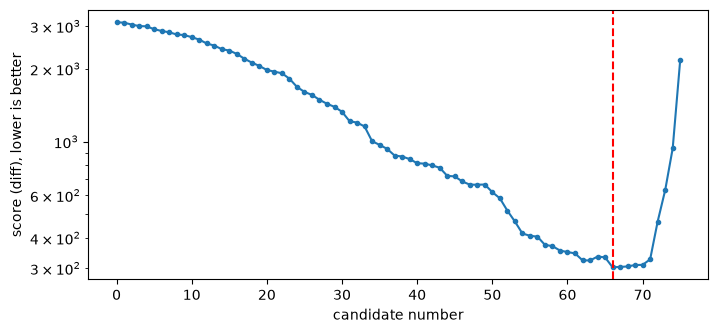

In [9]:
plt.figure(figsize=(8, 3.5))
plt.plot(result["diffs"], marker=".")
plt.axvline(best, color="red", linestyle="--")
plt.yscale("log")
plt.xlabel("candidate number")
plt.ylabel("score (diff), lower is better")
plt.show()

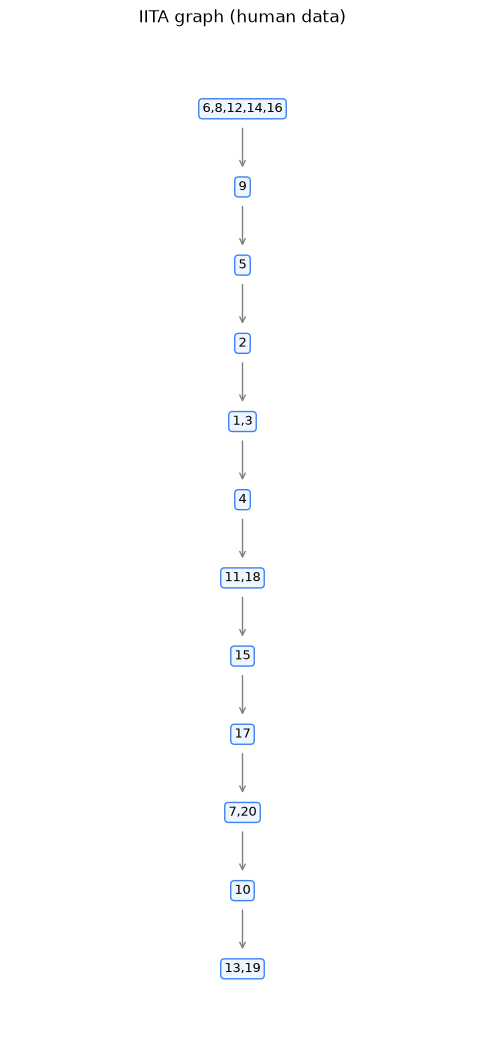

In [10]:
groups, cover_pairs = graph_from_pairs(human_pairs, list(range(1, 21)))
draw_graph(groups, cover_pairs, "IITA graph (human data)")

## Part 3: IITA graph vs Q-matrix graph

In [11]:
q_pairs = q_prerequisite_pairs(load_q_matrix(paths.TATSUOKA_Q_MATRIX))
common = q_pairs & human_pairs
only_q = q_pairs - human_pairs
only_iita = human_pairs - q_pairs
print("Q pairs:", len(q_pairs), "| IITA pairs:", len(human_pairs))
print("in both:", len(common), "| only Q:", len(only_q), "| only IITA:", len(only_iita))

Q pairs: 101 | IITA pairs: 204
in both: 91 | only Q: 10 | only IITA: 113


In [12]:
pd.DataFrame(
    [
        {
            "prerequisite": a,
            "of": b,
            "share correct (prerequisite)": round(shares[a], 2),
            "share correct (of)": round(shares[b], 2),
        }
        for a, b in sorted(only_q)
    ]
)

,prerequisite,of,share correct (prerequisite),share correct (of)
0,2,5,0.58,0.58
1,3,2,0.51,0.58
2,3,5,0.51,0.58
3,9,14,0.65,0.72
4,9,16,0.65,0.70
5,11,4,0.47,0.53
6,17,4,0.43,0.53
7,17,11,0.43,0.47
8,17,18,0.43,0.47
9,20,4,0.39,0.53


## Part 4: does the method work? (simulated students)

Students are generated from the Q-matrix graph with 5% random mistakes. If IITA works, it should find almost all Q pairs again.

In [13]:
simulated = simulate_answers(q_pairs, n_items=20, n_students=536, slip=0.05, guess=0.05, select_prob=0.2, seed=1)
simulated_pairs = run_iita(simulated)["relation"]
print("true pairs:", len(q_pairs), "| found:", len(simulated_pairs))
print("found correctly:", len(q_pairs & simulated_pairs), "| missed:", len(q_pairs - simulated_pairs), "| extra:", len(simulated_pairs - q_pairs))

true pairs: 101 | found: 120
found correctly: 99 | missed: 2 | extra: 21
